<a href="https://colab.research.google.com/github/encen-ya/ML_2026/blob/main/pertemuan_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS13 - Artificial Neural Network (ANN) dan Evaluasi Classifier

### Praktikum 1 JST sederhana

In [1]:
import numpy as np

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

# Output akhir
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.2913714915773717
Epoch 1000, Loss: 0.1895502922782575
Epoch 2000, Loss: 0.039548785842587364
Epoch 3000, Loss: 0.01397144706510084
Epoch 4000, Loss: 0.007783095933313514
Epoch 5000, Loss: 0.005246584290977087
Epoch 6000, Loss: 0.003907909888906841
Epoch 7000, Loss: 0.0030924836722885543
Epoch 8000, Loss: 0.002548069532691613
Epoch 9000, Loss: 0.0021607554081492252
Prediksi:
[[0.04790588]
 [0.95854823]
 [0.95899727]
 [0.04236633]]


### Tugas 1:

Ubah jumlah neuron hidden layer menjadi 3.

Bandingkan hasil loss dengan konfigurasi awal.

Tambahkan fungsi aktivasi ReLU dan bandingkan hasil.

Epoch 0, Loss: 0.255830
Epoch 1000, Loss: 0.249406
Epoch 2000, Loss: 0.245445
Epoch 3000, Loss: 0.204707
Epoch 4000, Loss: 0.153204
Epoch 5000, Loss: 0.138691
Epoch 6000, Loss: 0.133594
Epoch 7000, Loss: 0.131151
Epoch 8000, Loss: 0.129749
Epoch 9000, Loss: 0.128849
Prediksi hidden=2 sigmoid:
 [[0.053 ]
 [0.4955]
 [0.9509]
 [0.5032]]
Prediksi hidden=3 sigmoid:
 [[0.0252]
 [0.9526]
 [0.9512]
 [0.0627]]
Prediksi hidden=3 ReLU:
 [[0.0297]
 [0.9861]
 [0.9861]
 [0.0116]]


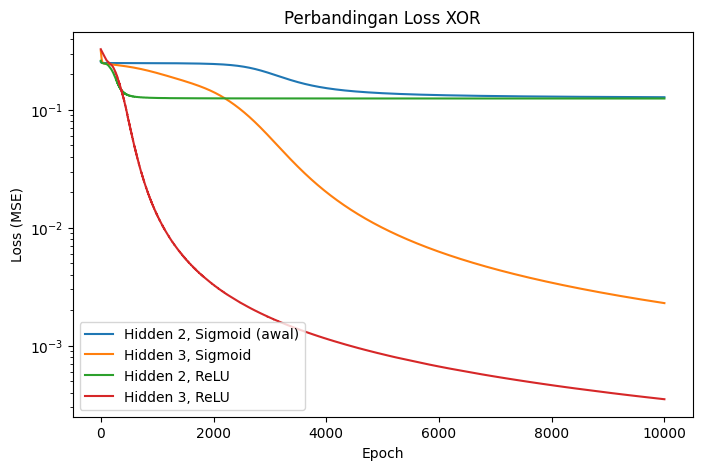

             Konfigurasi  Loss akhir (rata-rata)  Loss akhir (terbaik) Konvergen (loss<0.01)
Hidden 2, Sigmoid (awal)                0.040973              0.002433                  7/10
       Hidden 3, Sigmoid                0.002207              0.001713                 10/10
          Hidden 2, ReLU                0.187538              0.125051                  0/10
          Hidden 3, ReLU                0.104319              0.000213                  5/10


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def relu(x):
    return np.maximum(0, x)

def train_xor(hidden_size=2, hidden_act='sigmoid', lr=0.1, epochs=10000, seed=42):
    """JST 2 layer (input-hidden-output) dengan backpropagation manual.
       Output layer selalu sigmoid; aktivasi hidden bisa 'sigmoid' atau 'relu'."""
    rng = np.random.RandomState(seed)
    W1 = rng.randn(2, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = rng.randn(hidden_size, 1)
    b2 = np.zeros((1, 1))
    losses = []

    for epoch in range(epochs):
        # Forward pass
        z1 = X @ W1 + b1
        a1 = sigmoid(z1) if hidden_act == 'sigmoid' else relu(z1)
        z2 = a1 @ W2 + b2
        a2 = sigmoid(z2)

        # Error & loss (MSE)
        error = y - a2
        losses.append(np.mean(np.square(error)))

        # Backpropagation
        d_a2 = error * a2 * (1 - a2)
        d_W2 = a1.T @ d_a2
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        if hidden_act == 'sigmoid':
            d_a1 = (d_a2 @ W2.T) * a1 * (1 - a1)
        else:  # ReLU: turunan = 1 jika z1 > 0, selain itu 0
            d_a1 = (d_a2 @ W2.T) * (z1 > 0).astype(float)
        d_W1 = X.T @ d_a1
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot (gradient descent)
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    return a2, losses

# ===== 1. Konfigurasi awal (hidden = 2, sigmoid) =====
pred, losses = train_xor(hidden_size=2, hidden_act='sigmoid')
for e in range(0, 10000, 1000):
    print(f"Epoch {e}, Loss: {losses[e]:.6f}")
print("Prediksi hidden=2 sigmoid:\n", pred.round(4))

# ===== 2. Hidden layer = 3 neuron =====
pred3, losses3 = train_xor(hidden_size=3, hidden_act='sigmoid')
print("Prediksi hidden=3 sigmoid:\n", pred3.round(4))

# ===== 3. Tambah ReLU =====
pred_r, losses_r = train_xor(hidden_size=3, hidden_act='relu')
print("Prediksi hidden=3 ReLU:\n", pred_r.round(4))

# ===== Perbandingan loss (seed 42) =====
configs = {
    'Hidden 2, Sigmoid (awal)': dict(hidden_size=2, hidden_act='sigmoid'),
    'Hidden 3, Sigmoid':        dict(hidden_size=3, hidden_act='sigmoid'),
    'Hidden 2, ReLU':           dict(hidden_size=2, hidden_act='relu'),
    'Hidden 3, ReLU':           dict(hidden_size=3, hidden_act='relu'),
}

plt.figure(figsize=(8, 5))
for nama, cfg in configs.items():
    _, l = train_xor(**cfg)
    plt.plot(l, label=nama)
plt.xlabel('Epoch'); plt.ylabel('Loss (MSE)'); plt.yscale('log')
plt.title('Perbandingan Loss XOR'); plt.legend(); plt.show()

# ===== Uji ketahanan terhadap inisialisasi acak (10 seed) =====
rows = []
for nama, cfg in configs.items():
    finals = [train_xor(seed=s, **cfg)[1][-1] for s in range(10)]
    rows.append({
        'Konfigurasi': nama,
        'Loss akhir (rata-rata)': np.mean(finals),
        'Loss akhir (terbaik)': np.min(finals),
        'Konvergen (loss<0.01)': f"{sum(f < 0.01 for f in finals)}/10",
    })
print(pd.DataFrame(rows).to_string(index=False))

### Praktikum 2
menggunakan library Keras untuk menggunakan JST

In [11]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Bangun model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
model.fit(X_train, y_train, epochs=50, batch_size=8)

# Evaluasi
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi: {acc}")

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0000e+00 - loss: 1.9986  
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0000e+00 - loss: 1.6665 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0000e+00 - loss: 1.3813 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0000e+00 - loss: 1.1734 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2667 - loss: 1.0547     
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4500 - loss: 0.9929 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4000 - loss: 0.9518 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4250 - loss: 0.9164 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4583 - loss: 0.8832 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4917 - loss: 0.8510 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6750 - loss: 0.8194 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 

### Tugas 2
Ubah jumlah neuron hidden layer.

Bandingkan akurasi dengan konfigurasi awal.


   Hidden layer  Loss test  Akurasi test  Std akurasi
(10, 8)  [awal]     0.3809        0.9222       0.0629
         (4, 4)     0.8036        0.6222       0.2200
       (20, 16)     0.1290        1.0000       0.0000
       (64, 32)     0.0793        1.0000       0.0000
      (128, 64)     0.0593        1.0000       0.0000


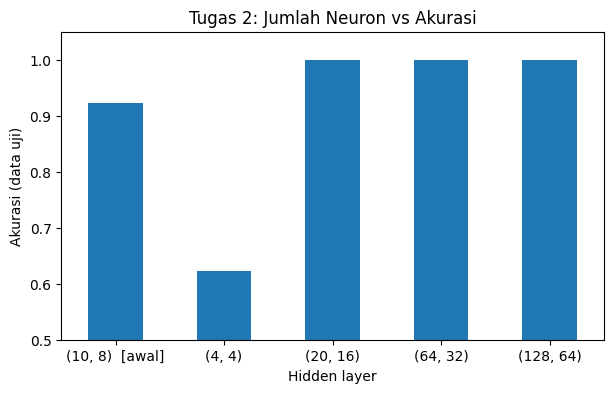

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# ===== Data =====
iris = load_iris()
X = iris.data
y = OneHotEncoder(sparse_output=False).fit_transform(iris.target.reshape(-1, 1))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=iris.target)

def build_iris_model(hidden_units, activation='relu'):
    layers = [tf.keras.layers.Input(shape=(4,))]
    for u in hidden_units:
        layers.append(tf.keras.layers.Dense(u, activation=activation))
    layers.append(tf.keras.layers.Dense(3, activation='softmax'))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def run_iris(hidden_units, activation='relu', seeds=(0, 1, 2), epochs=50):
    """Latih dengan beberapa seed, kembalikan rata-rata loss dan akurasi data uji."""
    losses, accs = [], []
    for s in seeds:
        tf.keras.utils.set_random_seed(s)
        model = build_iris_model(hidden_units, activation)
        model.fit(X_train, y_train, epochs=epochs, batch_size=8, verbose=0)
        l, a = model.evaluate(X_test, y_test, verbose=0)
        losses.append(l); accs.append(a)
    return np.mean(losses), np.mean(accs), np.std(accs)

# =========================================================
# TUGAS 2: Ubah jumlah neuron hidden layer
# =========================================================
konfigurasi = {
    '(10, 8)  [awal]': (10, 8),
    '(4, 4)':          (4, 4),
    '(20, 16)':        (20, 16),
    '(64, 32)':        (64, 32),
    '(128, 64)':       (128, 64),
}

rows = []
for nama, units in konfigurasi.items():
    loss, acc, std = run_iris(units, 'relu')
    rows.append({'Hidden layer': nama, 'Loss test': round(loss, 4),
                 'Akurasi test': round(acc, 4), 'Std akurasi': round(std, 4)})
tabel2 = pd.DataFrame(rows)
print(tabel2.to_string(index=False))

tabel2.plot(x='Hidden layer', y='Akurasi test', kind='bar', legend=False, ylim=(0.5, 1.05), figsize=(7, 4))
plt.ylabel('Akurasi (data uji)'); plt.title('Tugas 2: Jumlah Neuron vs Akurasi')
plt.xticks(rotation=0); plt.show()


### Tugas 3

Bandingkan Sigmoid vs ReLU pada dataset Iris.

Catat perbedaan loss dan akurasi.

Aktivasi  Loss test  Akurasi test  Std akurasi
 sigmoid     0.5453        0.8444       0.0314
    relu     0.3809        0.9222       0.0629


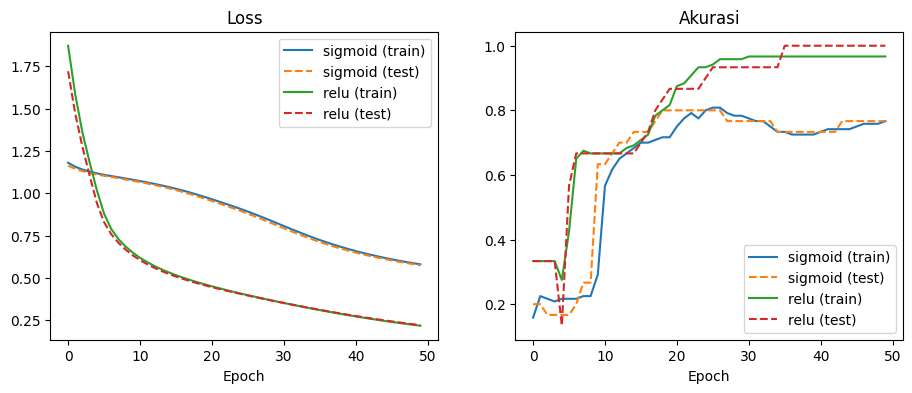

In [3]:
# =========================================================
# TUGAS 3: Sigmoid vs ReLU
# =========================================================
rows = []
for act in ['sigmoid', 'relu']:
    loss, acc, std = run_iris((10, 8), act)
    rows.append({'Aktivasi': act, 'Loss test': round(loss, 4),
                 'Akurasi test': round(acc, 4), 'Std akurasi': round(std, 4)})
tabel3 = pd.DataFrame(rows)
print(tabel3.to_string(index=False))

# Kurva loss & akurasi per epoch
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for act in ['sigmoid', 'relu']:
    tf.keras.utils.set_random_seed(42)
    model = build_iris_model((10, 8), act)
    h = model.fit(X_train, y_train, epochs=50, batch_size=8,
                  validation_data=(X_test, y_test), verbose=0)
    ax[0].plot(h.history['loss'], label=f'{act} (train)')
    ax[0].plot(h.history['val_loss'], '--', label=f'{act} (test)')
    ax[1].plot(h.history['accuracy'], label=f'{act} (train)')
    ax[1].plot(h.history['val_accuracy'], '--', label=f'{act} (test)')
ax[0].set_title('Loss'); ax[1].set_title('Akurasi')
for a in ax:
    a.set_xlabel('Epoch'); a.legend()
plt.show()

### Praktikum 3

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

# Evaluasi
print("Prediksi:", model.predict(X_test))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - loss: 2.6202
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - loss: 2.5910
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - loss: 2.5620
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - loss: 2.5333
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - loss: 2.5049
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - loss: 2.4767
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 2.4488
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - loss: 2.4212
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - loss: 2.3939
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - loss: 2.3669
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - loss: 2.3401
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 2.3136
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 2.2875
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 2.2616
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 2.2360
Epoch 16/100
1/1 

### Tugas 4:

Ubah learning rate.

Bandingkan hasil loss.

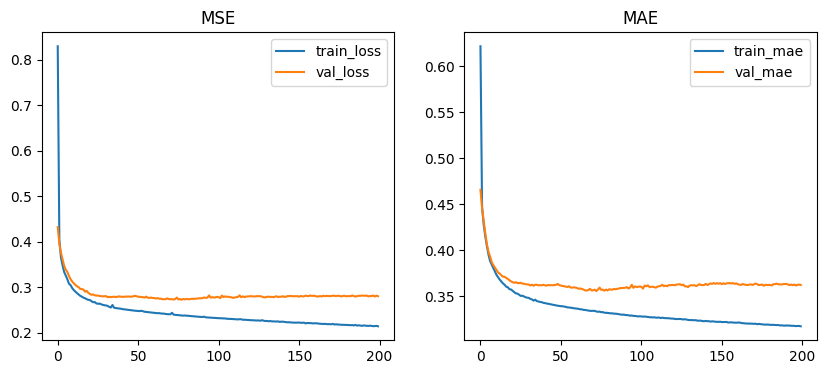

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
RMSE: 0.5289229147929141


In [7]:
# MLP regresi (Keras)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# 1. Load California Housing Dataset
data = fetch_california_housing()
X = data.data; y = data.target

# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

from sklearn.metrics import mean_squared_error
pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))

### Tugas Praktikum
Gunakan JST untuk klasifikasi angka tulisan tangan (MNIST).

Langkah:

Load dataset MNIST dari Keras.

Bangun model dengan 2 hidden layer.

Latih model dan evaluasi akurasi.

In [10]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data (0-255 → 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 2. Bangun model JST dengan 2 hidden layer menggunakan standard Input layer
model = Sequential([
    Input(shape=(28, 28)),          # Input layer
    Flatten(),                      # Ubah gambar 28x28 menjadi vektor 784
    Dense(128, activation='relu'), # Hidden layer 1
    Dense(64, activation='relu'),  # Hidden layer 2
    Dense(10, activation='softmax') # Output layer (10 kelas)
])

# 3. Kompilasi model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# 4. Latih model
model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

# 5. Evaluasi model
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi pada data uji: {acc:.4f}")

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9164 - loss: 0.2922 - val_accuracy: 0.9605 - val_loss: 0.1326
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9626 - loss: 0.1261 - val_accuracy: 0.9687 - val_loss: 0.1008
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9744 - loss: 0.0871 - val_accuracy: 0.9718 - val_loss: 0.0939
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9814 - loss: 0.0641 - val_accuracy: 0.9732 - val_loss: 0.0910
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9859 - loss: 0.0475 - val_accuracy: 0.9727 - val_loss: 0.0977
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9695 - loss: 0.0969
Akurasi pada data uji: 0.9695


Coba dengan beberapa parameter lain:

Ubah jumlah neuron di hidden layer (misal: 256 dan 128).

Tambahkan satu hidden layer lagi.

Bandingkan akurasi dan waktu pelatihan.

Eksperimen dengan fungsi aktivasi Sigmoid vs ReLU.

Model: "sequential_31"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_89 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_90 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_91 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9031 - loss: 0.3463 - val_accuracy: 0.9583 - val_loss: 0.1410
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9568 - loss: 0.1477 - val_accuracy: 0.9677 - val_loss: 0.1093
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9692 - loss: 0.1034 - val_accuracy: 0.9708 - val_loss: 0.0979
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9771 - loss: 0.0785 - val_accuracy: 0.9708 - val_loss: 0.0978
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9821 - loss: 0.0622 - val_accuracy: 0.9717 - val_loss: 0.0972
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9860 - loss: 0.0490 - val_accuracy: 0.9727 - val_loss: 0.0975
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9895 - loss: 0.0390 - val_accuracy: 0.9732 - val_loss: 0.0971
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9914 - loss: 0.0315 - val_accuracy: 0.

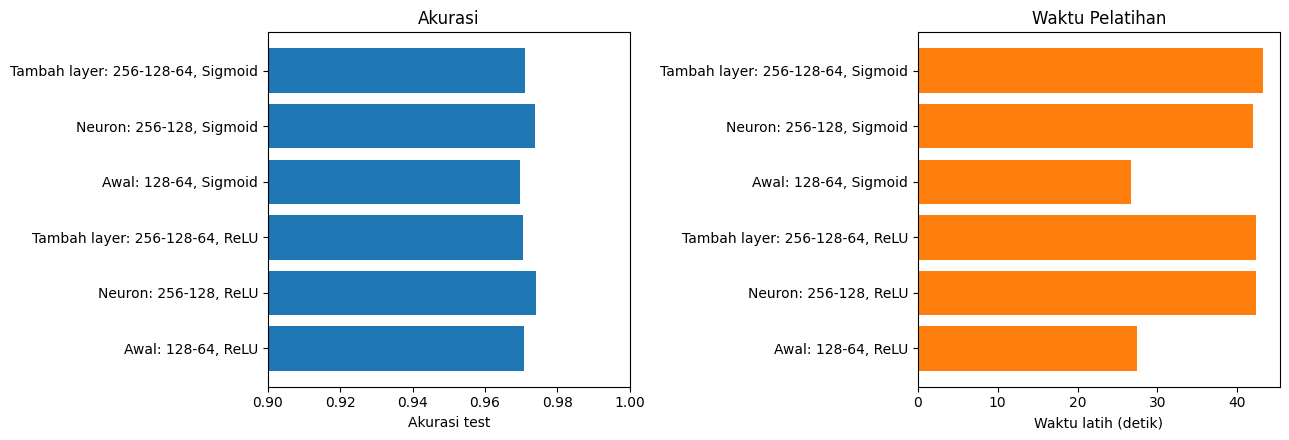

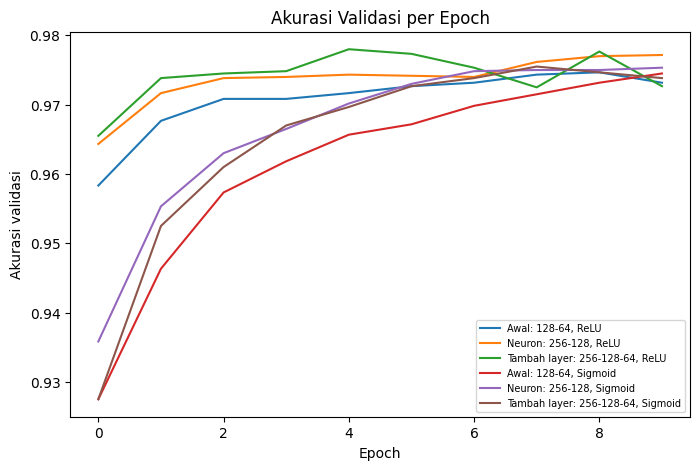

In [11]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import to_categorical

# ===== 1. Load dataset =====
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = X_train / 255.0
X_test = X_test / 255.0
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# ===== 2-5. Model dasar sesuai template modul (2 hidden layer) =====
tf.keras.utils.set_random_seed(42)
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),                           # ubah 28x28 menjadi vektor 784
    Dense(128, activation='relu'),       # hidden layer 1
    Dense(64, activation='relu'),        # hidden layer 2
    Dense(10, activation='softmax'),     # output layer (10 kelas)
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

model.fit(X_train, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=1)

loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi pada data uji: {acc:.4f}")

# ===== Eksperimen perbandingan =====
def build_mnist(units, activation):
    layers = [Input(shape=(28, 28)), Flatten()]
    for u in units:
        layers.append(Dense(u, activation=activation))
    layers.append(Dense(10, activation='softmax'))
    m = Sequential(layers)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

eksperimen = [
    ('Awal: 128-64, ReLU',             (128, 64),      'relu'),
    ('Neuron: 256-128, ReLU',          (256, 128),     'relu'),
    ('Tambah layer: 256-128-64, ReLU', (256, 128, 64), 'relu'),
    ('Awal: 128-64, Sigmoid',          (128, 64),      'sigmoid'),
    ('Neuron: 256-128, Sigmoid',       (256, 128),     'sigmoid'),
    ('Tambah layer: 256-128-64, Sigmoid', (256, 128, 64), 'sigmoid'),
]

hasil, riwayat = [], {}
for nama, units, act in eksperimen:
    tf.keras.utils.set_random_seed(42)
    m = build_mnist(units, act)
    t0 = time.perf_counter()
    h = m.fit(X_train, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=0)
    waktu = time.perf_counter() - t0
    l, a = m.evaluate(X_test, y_test, verbose=0)
    riwayat[nama] = h.history
    hasil.append({
        'Konfigurasi': nama,
        'Parameter': m.count_params(),
        'Akurasi test': round(a, 4),
        'Loss test': round(l, 4),
        'Waktu latih (detik)': round(waktu, 1),
    })
    print(f'{nama}: acc={a:.4f}, waktu={waktu:.1f}s')

tabel = pd.DataFrame(hasil)
print(tabel.to_string(index=False))

# ===== Visualisasi =====
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh(tabel['Konfigurasi'], tabel['Akurasi test'])
ax[0].set_xlim(0.9, 1.0); ax[0].set_xlabel('Akurasi test'); ax[0].set_title('Akurasi')
ax[1].barh(tabel['Konfigurasi'], tabel['Waktu latih (detik)'], color='tab:orange')
ax[1].set_xlabel('Waktu latih (detik)'); ax[1].set_title('Waktu Pelatihan')
plt.tight_layout(); plt.show()

# Kurva akurasi validasi per epoch
plt.figure(figsize=(8, 5))
for nama, h in riwayat.items():
    plt.plot(h['val_accuracy'], label=nama)
plt.xlabel('Epoch'); plt.ylabel('Akurasi validasi'); plt.legend(fontsize=7)
plt.title('Akurasi Validasi per Epoch'); plt.show()